# Moduł przeznaczony do wstępnej analizy danych (rozkłady, wartości, wizualizacja, testy statystyczne)

import bibliotek

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

## załadowanie zbioru danych - mozemy korzystac tylko ze zbioru połączonych obserwacji

In [5]:
data = pd.read_csv('C:/Licencjat_DS/data/processed/df_merged.csv', index_col = 0)

## Podstawowe informacje o danych

In [6]:
print(data.head())

   PolicyID  ClaimNb  Exposure Power  CarAge  DriverAge  \
0         1        0      0.09     g       0         46   
1         2        0      0.84     g       0         46   
2         3        0      0.52     f       2         38   
3         4        0      0.45     f       2         38   
4         5        0      0.15     g       0         41   

                                Brand      Gas              Region  Density  \
0  Japanese (except Nissan) or Korean   Diesel           Aquitaine       76   
1  Japanese (except Nissan) or Korean   Diesel           Aquitaine       76   
2  Japanese (except Nissan) or Korean  Regular  Nord-Pas-de-Calais     3003   
3  Japanese (except Nissan) or Korean  Regular  Nord-Pas-de-Calais     3003   
4  Japanese (except Nissan) or Korean   Diesel    Pays-de-la-Loire       60   

   TotalClaimAmount  ClaimCount  
0               0.0         0.0  
1               0.0         0.0  
2               0.0         0.0  
3               0.0         0.0  


In [7]:
print(data.dtypes)

PolicyID              int64
ClaimNb               int64
Exposure            float64
Power                object
CarAge                int64
DriverAge             int64
Brand                object
Gas                  object
Region               object
Density               int64
TotalClaimAmount    float64
ClaimCount          float64
dtype: object


In [8]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
Index: 413169 entries, 0 to 413168
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   PolicyID          413169 non-null  int64  
 1   ClaimNb           413169 non-null  int64  
 2   Exposure          413169 non-null  float64
 3   Power             413169 non-null  object 
 4   CarAge            413169 non-null  int64  
 5   DriverAge         413169 non-null  int64  
 6   Brand             413169 non-null  object 
 7   Gas               413169 non-null  object 
 8   Region            413169 non-null  object 
 9   Density           413169 non-null  int64  
 10  TotalClaimAmount  413169 non-null  float64
 11  ClaimCount        413169 non-null  float64
dtypes: float64(3), int64(5), object(4)
memory usage: 41.0+ MB
None


## Rozkłady zmiennych ClaimNb, Exposure, ClaimAmount

### Zmienna - ClaimNb

wartosci wystepujace w danych

In [14]:
data["ClaimNb"].value_counts().sort_index()

ClaimNb
0    397779
1     14633
2       726
3        28
4         3
Name: count, dtype: int64

udzial wartosci w danych

In [15]:
claim_dist = (
    data["ClaimNb"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(claim_dist.rename("percentage").to_frame())

,percentage
ClaimNb,
0,96.275132
1,3.541650
2,0.175715
3,0.006777
4,0.000726


charakterystyka liczbowa wartosci

In [13]:
print(data['ClaimNb'].describe())

count    413169.000000
mean          0.039163
std           0.204053
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
Name: ClaimNb, dtype: float64


wykres rozkladu

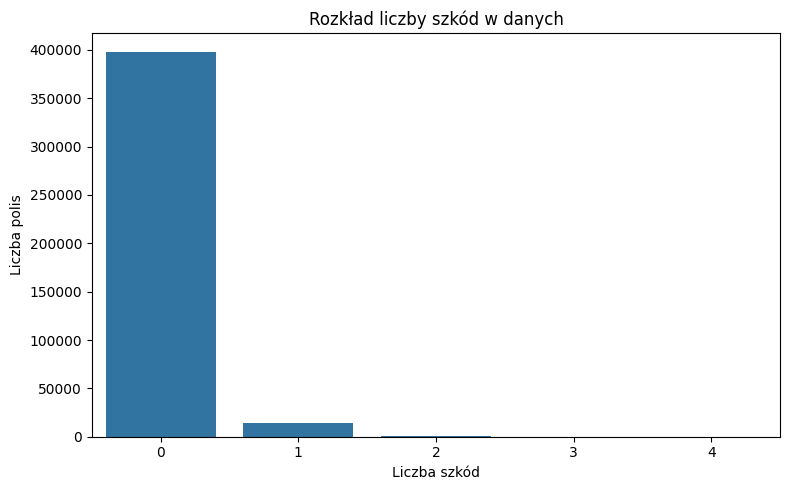

In [16]:

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="ClaimNb")

plt.title("Rozkład liczby szkód w danych")
plt.xlabel("Liczba szkód")
plt.ylabel("Liczba polis")
plt.tight_layout()
plt.show()

### Zmienna - ekspozycja

In [17]:
data["Exposure"].value_counts().sort_index()

Exposure
0.002732       711
0.002740      1325
0.005464       392
0.005479       811
0.008197       390
             ...  
0.960000      2120
0.970000       971
0.980000      1104
0.990000      1032
1.000000    122038
Name: count, Length: 106, dtype: int64

In [19]:
exposure_dist = (
    data["Exposure"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(exposure_dist.rename("percentage").to_frame())

,percentage
Exposure,
0.002732,0.172085
0.002740,0.320692
0.005464,0.094876
0.005479,0.196288
0.008197,0.094392
...,...
0.960000,0.513107
0.970000,0.235013
0.980000,0.267203


In [20]:
print(data['Exposure'].describe())

count    413169.000000
mean          0.560982
std           0.369304
min           0.002732
25%           0.200000
50%           0.540000
75%           1.000000
max           1.000000
Name: Exposure, dtype: float64


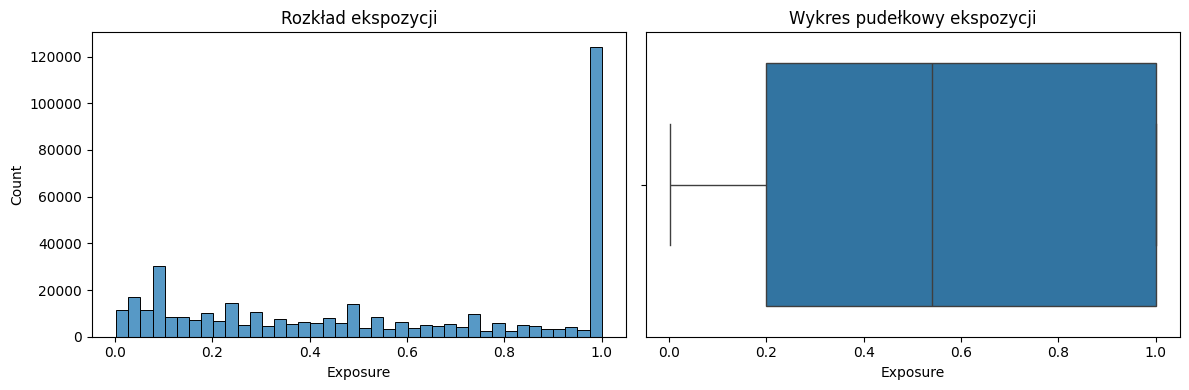

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=data, x="Exposure", bins=40, ax=axes[0])
axes[0].set_title("Rozkład ekspozycji")

sns.boxplot(data=data, x="Exposure", ax=axes[1])
axes[1].set_title("Wykres pudełkowy ekspozycji")

plt.tight_layout()
plt.show()

### Zmienna - TotalClaimsAmount

In [31]:
data["TotalClaimAmount"].value_counts().sort_index()

TotalClaimAmount
0.0          397779
2.0               3
3.0               3
4.0               2
5.0               4
              ...  
281403.0          1
301302.0          1
306559.0          1
1403452.0         1
2036833.0         1
Name: count, Length: 3709, dtype: int64

In [35]:
claim_dist = (
    data[data["TotalClaimAmount"] > 0]['TotalClaimAmount']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(claim_dist.rename("percentage").to_frame())

,percentage
TotalClaimAmount,
2.0,0.019493
3.0,0.019493
4.0,0.012995
5.0,0.025991
6.0,0.012995
...,...
281403.0,0.006498
301302.0,0.006498
306559.0,0.006498


In [37]:
print(data['TotalClaimAmount'].describe())

count    4.131690e+05
mean     8.341642e+01
std      4.192526e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.036833e+06
Name: TotalClaimAmount, dtype: float64


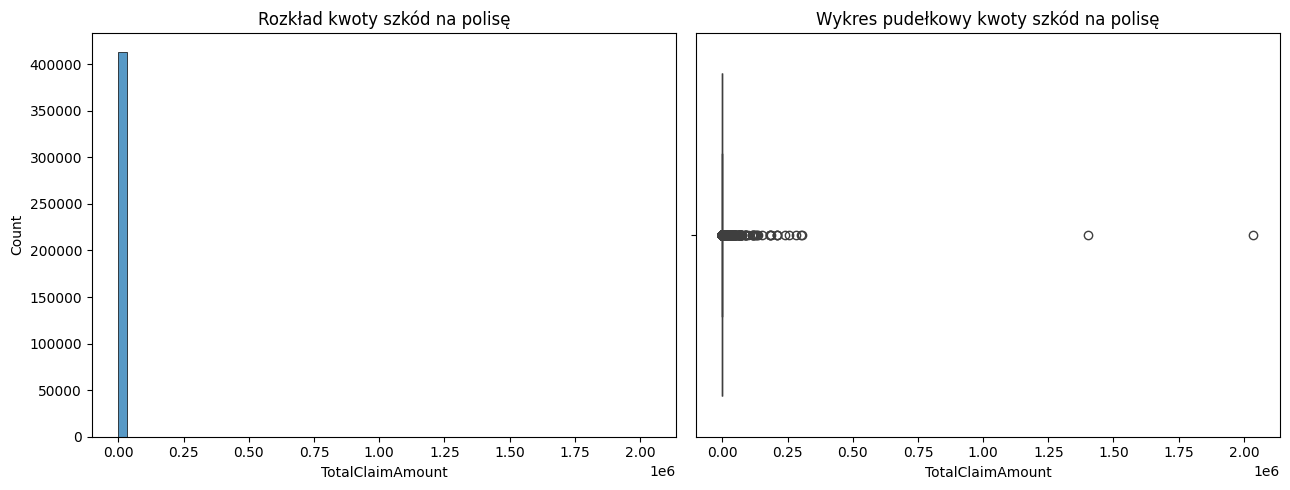

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=data, x="TotalClaimAmount", bins=60, ax=axes[0])
axes[0].set_title("Rozkład kwoty szkód na polisę")

sns.boxplot(data=data, x="TotalClaimAmount", ax=axes[1])
axes[1].set_title("Wykres pudełkowy kwoty szkód na polisę")

plt.tight_layout()
plt.show()

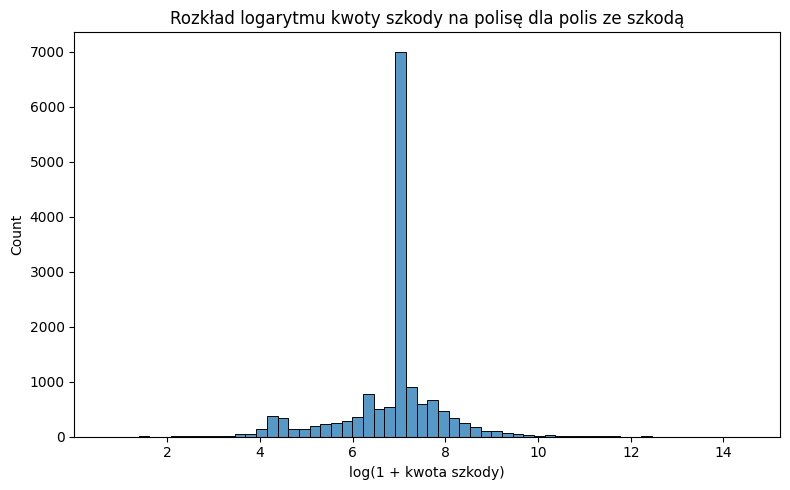

In [30]:
plt.figure(figsize=(8, 5))

sns.histplot(
    np.log(data.loc[data["TotalClaimAmount"] > 0, "TotalClaimAmount"]),
    bins=60
)

plt.title("Rozkład logarytmu kwoty szkody na polisę dla polis ze szkodą")
plt.xlabel("log(1 + kwota szkody)")
plt.tight_layout()
plt.show()

### Analiza danych ze względu na liczbę szkód

In [38]:
claim_summary = (
    data.groupby("ClaimNb", observed=True)
      .agg(
          policies=("ClaimNb", "size"),
          mean_total_claim=("TotalClaimAmount", "mean"),
          median_total_claim=("TotalClaimAmount", "median"),
          total_claims_amount=("TotalClaimAmount", "sum")
      )
)

display(claim_summary)

,policies,mean_total_claim,median_total_claim,total_claims_amount
ClaimNb,,,,
0,397779,0.000000,0.0,0.0
1,14633,2040.914372,1156.0,29864700.0
2,726,6065.068871,2245.0,4403240.0
3,28,6509.285714,3645.5,182260.0
4,3,4959.000000,4811.0,14877.0


### Analiza wartości szkód

In [39]:
claims = data.loc[data["ClaimNb"] > 0].copy()

claims["ClaimSeverity"] = (
    claims["TotalClaimAmount"] / claims["ClaimNb"]
)

display(
    claims["ClaimSeverity"]
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
)

count    1.539000e+04
mean     2.087771e+03
std      1.915374e+04
min      2.000000e+00
50%      1.156000e+03
75%      1.245000e+03
90%      2.583100e+03
95%      4.269100e+03
99%      1.610336e+04
max      2.036833e+06
Name: ClaimSeverity, dtype: float64